# K-Means Clustering

## 1. Objective

The objective of this experiment is to understand and implement the K-Means Clustering algorithm using the Iris dataset.

The experiment focuses on:

- Understanding the concept of unsupervised learning.
- Implementing the K-Means clustering algorithm.
- Grouping similar data points into clusters.
- Understanding cluster centroids.
- Applying feature scaling.
- Visualizing clusters and centroids.
- Evaluating clustering performance using appropriate metrics.
- Comparing generated clusters with the actual Iris species for analysis.



## 2. Theory

### What is Clustering?

Clustering is an unsupervised machine learning technique that groups similar data points into clusters based on their feature similarities.

Data points within the same cluster are expected to be more similar to each other, while data points belonging to different clusters are expected to be less similar.

### What is K-Means?

K-Means is an unsupervised clustering algorithm that partitions a dataset into K clusters.

Each cluster is represented by a centroid, which is the mean position of all data points assigned to that cluster.

The algorithm attempts to minimize the within-cluster sum of squared distances between data points and their assigned cluster centroids.

### Objective Function

The objective of K-Means is to minimize the Within-Cluster Sum of Squares (WCSS).

\[
WCSS = \sum_{j=1}^{K}\sum_{x_i \in C_j}
\|x_i-\mu_j\|^2
\]

Where:

- K = Number of clusters
- Cj = Set of data points in cluster j
- xi = Data point
- μj = Centroid of cluster j

### Steps of K-Means

1. Select the number of clusters, K.
2. Initialize K cluster centroids.
3. Calculate the distance between each data point and every centroid.
4. Assign each data point to its nearest centroid.
5. Update the centroids by calculating the mean of assigned data points.
6. Repeat assignment and centroid update steps until convergence or the maximum number of iterations is reached.

### Applications

- Customer segmentation
- Image segmentation
- Document clustering
- Market analysis
- Pattern recognition
- Anomaly exploration



## 3. Dataset Information

**Dataset Name:** Iris Species Dataset

**Source:** Kaggle

**Dataset Link:** https://www.kaggle.com/datasets/uciml/iris

The Iris dataset contains 150 flower samples from three species.

Each sample is described by four numerical features:

| Feature | Description |
|---|---|
| SepalLengthCm | Sepal length |
| SepalWidthCm | Sepal width |
| PetalLengthCm | Petal length |
| PetalWidthCm | Petal width |

The Species column contains the actual species labels.

For K-Means clustering, the Species column will not be used during model training because K-Means is an unsupervised algorithm.

The actual species labels will only be used later to compare the generated clusters with the original flower categories.



## 4. Import Required Libraries

The following libraries are used for data manipulation, visualization, feature scaling, clustering, and evaluation.

- Pandas: Data manipulation
- NumPy: Numerical operations
- Matplotlib: Visualization
- Seaborn: Statistical visualization
- Scikit-learn: Feature scaling, K-Means, and evaluation metrics
- KaggleHub: Downloading the dataset from Kaggle


In [1]:
# Install KaggleHub if required
!pip install -q kagglehub

In [ ]:
# Import libraries

import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    confusion_matrix
)

import os

# Set visualization style
sns.set_style("whitegrid")


## 5. Load Dataset

The Iris dataset is downloaded directly from Kaggle using KaggleHub.

The downloaded CSV file is loaded into a Pandas DataFrame for further analysis.


In [7]:
# Download dataset from Kaggle
import kagglehub
import os

path = kagglehub.dataset_download("uciml/iris")

print("Dataset Path:", path)
print("Files:", os.listdir(path))

Using Colab cache for faster access to the 'iris' dataset.
Dataset Path: /kaggle/input/iris
Files: ['Iris.csv', 'database.sqlite']


In [9]:
# Load dataset
import pandas as pd
import os

df = pd.read_csv(os.path.join(path, "Iris.csv"))

# Display first 5 rows
display(df.head())

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


## 6. Dataset Exploration

Before applying K-Means, the dataset is explored to understand its structure, features, data types, and statistical properties.


In [10]:
# Dataset shape

print("Dataset Shape:", df.shape)

Dataset Shape: (150, 6)


In [11]:
# Dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [12]:
# Statistical summary

display(df.describe())

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


In [13]:
# Check missing values

print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64


In [14]:
# Check duplicate records

print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [15]:
# Check unique species

print("Unique Species:")
print(df["Species"].unique())

print("\nSpecies Distribution:")
print(df["Species"].value_counts())

Unique Species:
['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']

Species Distribution:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64



## 7. Data Preprocessing

### Removing Unnecessary Columns

The Id column contains sample identifiers rather than meaningful measurements.

Therefore, it is removed before clustering.

### Separating Features

Only numerical flower measurements are used as input features.

The Species column is excluded from model training because K-Means is an unsupervised learning algorithm.

The actual species labels are preserved separately for later evaluation.


In [16]:
# Remove unnecessary ID column

df = df.drop(columns=["Id"])

# Store actual species labels for evaluation
actual_species = df["Species"]

# Select numerical features
X = df.drop(columns=["Species"])

# Display features
display(X.head())

print("Feature Shape:", X.shape)

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Feature Shape: (150, 4)



### Feature Scaling

K-Means uses distance calculations to assign data points to clusters.

Features with larger numerical ranges may dominate the distance calculation.

StandardScaler transforms features so that they have approximately zero mean and unit variance.

This ensures that all features contribute more equally to the clustering process.


In [18]:
# Apply StandardScaler
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# Convert scaled data into DataFrame
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

display(X_scaled_df.head())

print("Scaled Data Shape:", X_scaled_df.shape)

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,-0.900681,1.032057,-1.341272,-1.312977
1,-1.143017,-0.124958,-1.341272,-1.312977
2,-1.385353,0.337848,-1.398138,-1.312977
3,-1.506521,0.106445,-1.284407,-1.312977
4,-1.021849,1.263460,-1.341272,-1.312977


Scaled Data Shape: (150, 4)


## 8. Implement K-Means Clustering

The Iris dataset contains three actual flower species.

Therefore, K is initially set to 3 to investigate whether K-Means can identify three groups from the numerical features.

The model is trained using the scaled features without using the actual species labels.


In [20]:
# Initialize K-Means
from sklearn.cluster import KMeans

k = 3

kmeans = KMeans(
    n_clusters=k,
    init="k-means++",
    n_init=10,
    max_iter=300,
    random_state=42
)

Parameter explanation:
- n_clusters=3 → Number of clusters.
- init="k-means++" → Smart centroid initialization.
- n_init=10 → Runs clustering 10 times with different initializations and selects the best result.
- max_iter=300 → Maximum iterations per run.
- random_state=42 → Ensures reproducibility.

In [21]:
# Fit the model

kmeans.fit(X_scaled)

print("K-Means Training Completed!")

K-Means Training Completed!


### Cluster Assignment

After training, every data point is assigned to one of the three clusters.

Cluster labels are generated by the algorithm and do not represent the actual flower species.


In [22]:
# Predict cluster labels

cluster_labels = kmeans.labels_

print("Cluster Labels:")
print(cluster_labels)

print("\nNumber of Labels:", len(cluster_labels))

Cluster Labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]

Number of Labels: 150


In [23]:
# Add cluster labels to the dataset

df["Cluster"] = cluster_labels

display(df.head(10))

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,Cluster
0,5.1,3.5,1.4,0.2,Iris-setosa,1
1,4.9,3.0,1.4,0.2,Iris-setosa,1
2,4.7,3.2,1.3,0.2,Iris-setosa,1
3,4.6,3.1,1.5,0.2,Iris-setosa,1
4,5.0,3.6,1.4,0.2,Iris-setosa,1
5,5.4,3.9,1.7,0.4,Iris-setosa,1
6,4.6,3.4,1.4,0.3,Iris-setosa,1
7,5.0,3.4,1.5,0.2,Iris-setosa,1
8,4.4,2.9,1.4,0.2,Iris-setosa,1
9,4.9,3.1,1.5,0.1,Iris-setosa,1


In [24]:
# Count samples in each cluster

print("Cluster Distribution:")
print(df["Cluster"].value_counts().sort_index())

Cluster Distribution:
Cluster
0    53
1    50
2    47
Name: count, dtype: int64


## 9. Cluster Centroids

A centroid represents the center of a cluster.

K-Means updates each centroid by calculating the mean of all data points assigned to that cluster.

The final centroids indicate the average standardized feature values of each cluster.


In [25]:
# Display cluster centroids

centroids = kmeans.cluster_centers_

centroid_df = pd.DataFrame(
    centroids,
    columns=X.columns
)

centroid_df.index.name = "Cluster"

display(centroid_df)

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
Cluster,,,,
0,-0.050220,-0.880292,0.347532,0.282063
1,-1.014579,0.842307,-1.304878,-1.255129
2,1.135970,0.096598,0.996271,1.017172



### Interpretation

The centroid values are expressed in standardized feature space because the model was trained on scaled data.

Centroids with similar feature values represent clusters with similar average characteristics.

Centroids with different petal measurements may indicate groups of flowers with different petal characteristics.


In [26]:
# Inverse transform scaled centroids

centroids_original = scaler.inverse_transform(
    kmeans.cluster_centers_
)

centroids_original_df = pd.DataFrame(
    centroids_original,
    columns=X.columns
)

centroids_original_df.index.name = "Cluster"

display(centroids_original_df)

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
Cluster,,,,
0,5.801887,2.673585,4.369811,1.413208
1,5.006000,3.418000,1.464000,0.244000
2,6.780851,3.095745,5.510638,1.972340



## 10. Cluster Visualization

The clusters are visualized using PetalLengthCm and PetalWidthCm.

Although the model uses all four standardized features, the visualization displays only two features for easier interpretation.

The cluster centroids are also displayed on the plot.


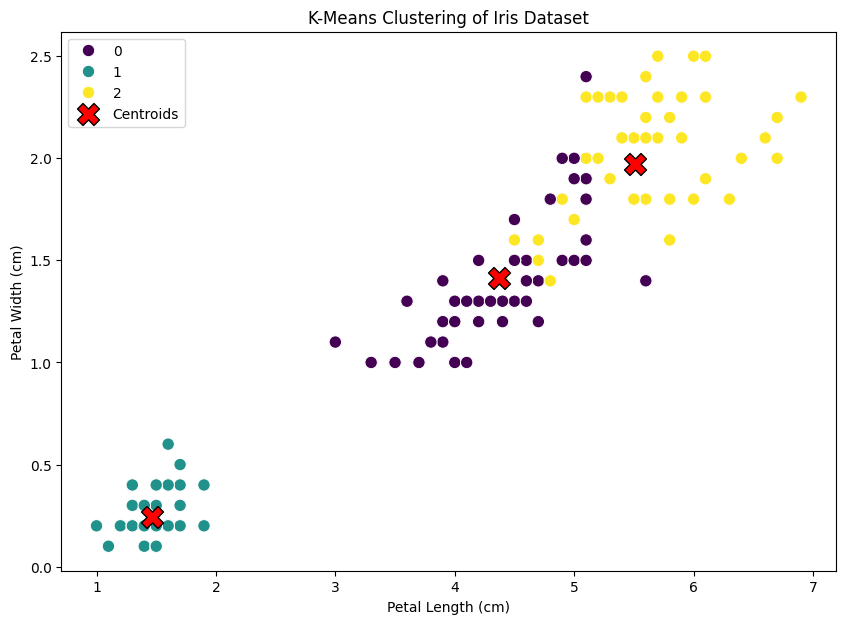

In [28]:
# Visualize clusters using petal measurements
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X["PetalLengthCm"],
    y=X["PetalWidthCm"],
    hue=cluster_labels,
    palette="viridis",
    s=80
)

# Plot centroids in original feature scale
plt.scatter(
    centroids_original[:, 2],
    centroids_original[:, 3],
    marker="X",
    s=250,
    color="red",
    edgecolor="black",
    label="Centroids"
)

plt.title("K-Means Clustering of Iris Dataset")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")

plt.legend()
plt.show()

### Observation

The scatter plot shows the clusters formed by K-Means based on the numerical features.

The centroids represent the central positions of the clusters.

Some clusters may be clearly separated, while some data points may overlap because the Iris species have similar characteristics.


### Principal Component Analysis (PCA)

PCA is used to reduce the dimensionality of the standardized feature space from four dimensions to two dimensions for visualization.

The K-Means model is still trained using all four features.

PCA is applied only to visualize the clustering results in a two-dimensional space.


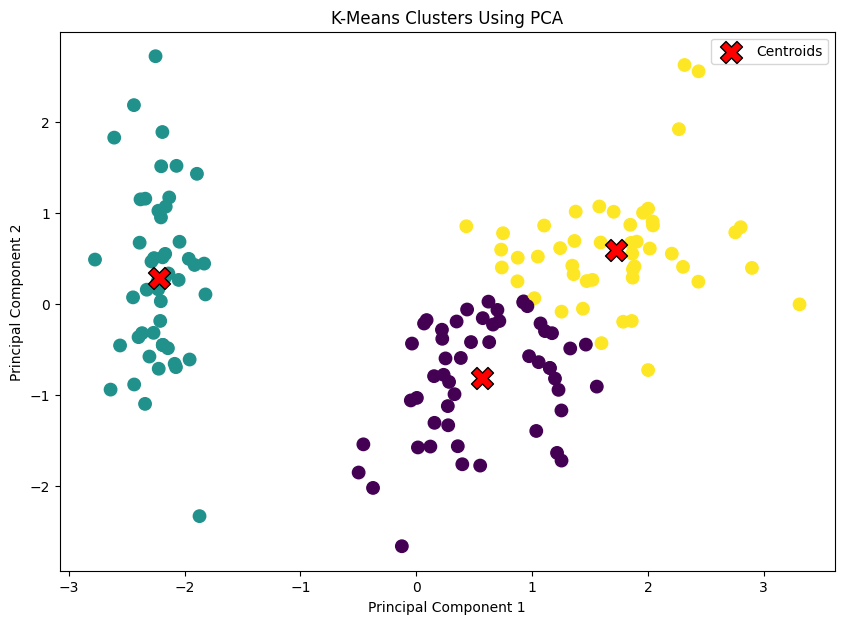

In [29]:
from sklearn.decomposition import PCA

# Reduce 4 dimensions to 2 dimensions
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Transform cluster centroids into PCA space
centroids_pca = pca.transform(kmeans.cluster_centers_)

# Visualize
plt.figure(figsize=(10, 7))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cluster_labels,
    cmap="viridis",
    s=80
)

plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    marker="X",
    s=250,
    color="red",
    edgecolor="black",
    label="Centroids"
)

plt.title("K-Means Clusters Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend()
plt.show()

In [30]:
# Explained variance

print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print(
    "\nTotal Variance Explained:",
    pca.explained_variance_ratio_.sum()
)

Explained Variance Ratio:
[0.72770452 0.23030523]

Total Variance Explained: 0.9580097536148199



### Observation

PCA projects the original four-dimensional dataset into two dimensions.

The visualization helps observe the separation and overlap between the generated clusters.

The two principal components preserve as much variance as possible under the two-dimensional projection, but some information from the original feature space is lost.



## 11. Optimal Number of Clusters

The Elbow Method is used to estimate an appropriate number of clusters.

For different values of K, the K-Means algorithm is trained and the Within-Cluster Sum of Squares (WCSS) is calculated.

WCSS measures the sum of squared distances between each data point and its assigned cluster centroid.

As K increases, WCSS generally decreases.

The optimal K can be estimated by identifying the elbow point, where the rate of decrease in WCSS becomes slower.


In [31]:
# Calculate WCSS for different values of K

wcss = []

for i in range(1, 11):

    model = KMeans(
        n_clusters=i,
        init="k-means++",
        n_init=10,
        max_iter=300,
        random_state=42
    )

    model.fit(X_scaled)

    wcss.append(model.inertia_)

print("WCSS Values:")
print(wcss)

WCSS Values:
[600.0000000000003, 223.73200573676343, 140.96581663074699, 114.61788585776682, 91.29544474066981, 81.75658187204954, 71.3198209518879, 62.65176715031903, 55.26184119603463, 50.62316902954043]


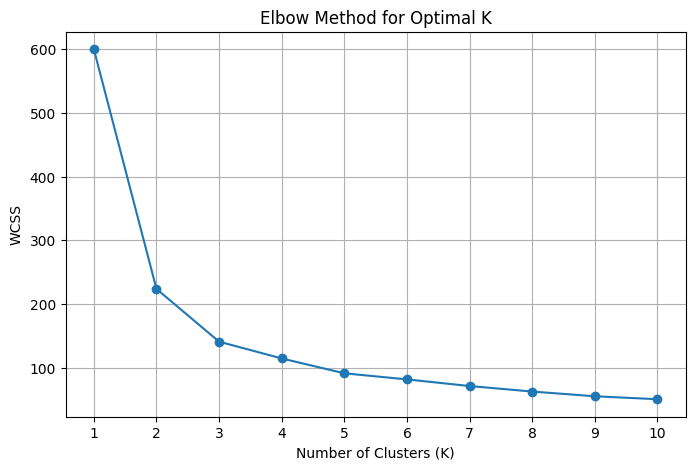

In [32]:
# Plot Elbow Method

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker="o"
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")

plt.xticks(range(1, 11))
plt.grid(True)

plt.show()


### Interpretation

The WCSS decreases as the number of clusters increases.

The elbow point represents a value of K where adding more clusters provides relatively smaller improvement in clustering compactness.

For the Iris dataset, K = 3 is considered a reasonable choice because the dataset contains three known species and the elbow plot can be examined to assess whether three clusters provide a suitable grouping.



##  Clustering Evaluation

### Silhouette Score

The Silhouette Score evaluates how well each data point fits within its assigned cluster compared to other clusters.

The score ranges from -1 to +1.

- Close to +1: Data points are well matched to their own cluster and separated from other clusters.
- Around 0: Clusters may overlap.
- Close to -1: Data points may have been assigned to an incorrect cluster.

Silhouette Score is an internal clustering evaluation metric because it evaluates cluster structure without requiring actual class labels.


In [34]:
# Calculate Silhouette Score
from sklearn.metrics import silhouette_score

sil_score = silhouette_score(
    X_scaled,
    cluster_labels
)

print("Silhouette Score:", sil_score)

Silhouette Score: 0.4589717867018717


In [35]:
# Calculate Inertia

print("Inertia (WCSS):", kmeans.inertia_)

Inertia (WCSS): 140.96581663074699



### Interpretation

Inertia measures the total squared distance between data points and their assigned cluster centroids.

Lower inertia indicates more compact clusters.

However, inertia always decreases as the number of clusters increases, so it should not be used alone to determine the optimal number of clusters.



## 13. Comparison with Actual Species

The Iris dataset contains actual species labels.

These labels were not used during model training.

In this section, the generated clusters are compared with the original species labels to understand how well the algorithm grouped similar flowers.

Since cluster labels are arbitrary, Cluster 0 does not necessarily represent Iris-setosa, Cluster 1 does not necessarily represent Iris-versicolor, and Cluster 2 does not necessarily represent Iris-virginica.


In [36]:
# Create comparison DataFrame

comparison_df = pd.DataFrame({
    "Actual Species": actual_species,
    "Predicted Cluster": cluster_labels
})

display(comparison_df.head(10))

,Actual Species,Predicted Cluster
0,Iris-setosa,1
1,Iris-setosa,1
2,Iris-setosa,1
3,Iris-setosa,1
4,Iris-setosa,1
5,Iris-setosa,1
6,Iris-setosa,1
7,Iris-setosa,1
8,Iris-setosa,1
9,Iris-setosa,1


In [37]:
# Compare actual species with predicted clusters

comparison_table = pd.crosstab(
    comparison_df["Actual Species"],
    comparison_df["Predicted Cluster"]
)

display(comparison_table)

Predicted Cluster,0,1,2
Actual Species,,,
Iris-setosa,0,50,0
Iris-versicolor,39,0,11
Iris-virginica,14,0,36


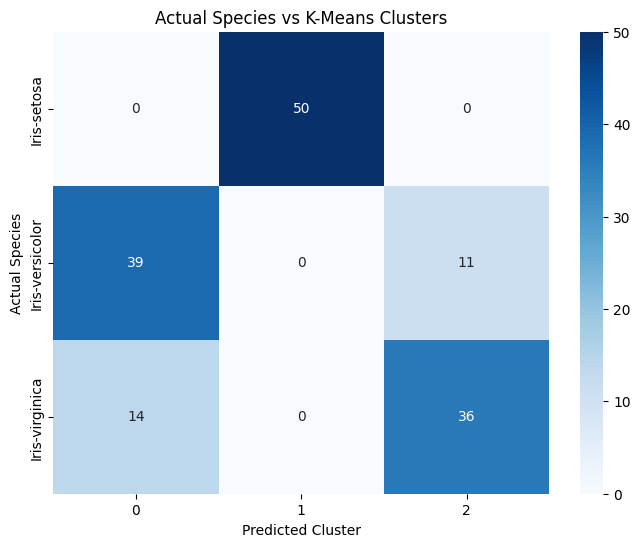

In [38]:
# Visualize comparison

plt.figure(figsize=(8, 6))

sns.heatmap(
    comparison_table,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Actual Species vs K-Means Clusters")
plt.xlabel("Predicted Cluster")
plt.ylabel("Actual Species")

plt.show()


### Interpretation

The comparison table shows how samples from each actual species are distributed across the generated clusters.

A cluster containing mostly samples from one species indicates that the algorithm identified similar feature patterns.

Some species may be distributed across multiple clusters or share a cluster because their feature characteristics overlap.



### Adjusted Rand Index

The Adjusted Rand Index (ARI) measures the similarity between the generated clusters and the actual class labels.

ARI adjusts the Rand Index for chance grouping.

Its values generally range from -1 to 1.

- 1: Perfect agreement between clustering and actual labels.
- 0: Similarity equivalent to random grouping.
- Negative values: Agreement worse than random expectation.

ARI is used here only for evaluation. The actual species labels are not used for model training.


In [40]:
# Calculate Adjusted Rand Index
from sklearn.metrics import adjusted_rand_score

ari_score = adjusted_rand_score(
    actual_species,
    cluster_labels
)

print("Adjusted Rand Index:", ari_score)

Adjusted Rand Index: 0.6201351808870379


In [41]:
# Display all evaluation metrics

print("=" * 40)
print("K-MEANS CLUSTERING RESULTS")
print("=" * 40)

print("Number of Clusters:", kmeans.n_clusters)
print("Number of Iterations:", kmeans.n_iter_)
print("Inertia (WCSS):", round(kmeans.inertia_, 4))
print("Silhouette Score:", round(sil_score, 4))
print("Adjusted Rand Index:", round(ari_score, 4))

K-MEANS CLUSTERING RESULTS
Number of Clusters: 3
Number of Iterations: 4
Inertia (WCSS): 140.9658
Silhouette Score: 0.459
Adjusted Rand Index: 0.6201


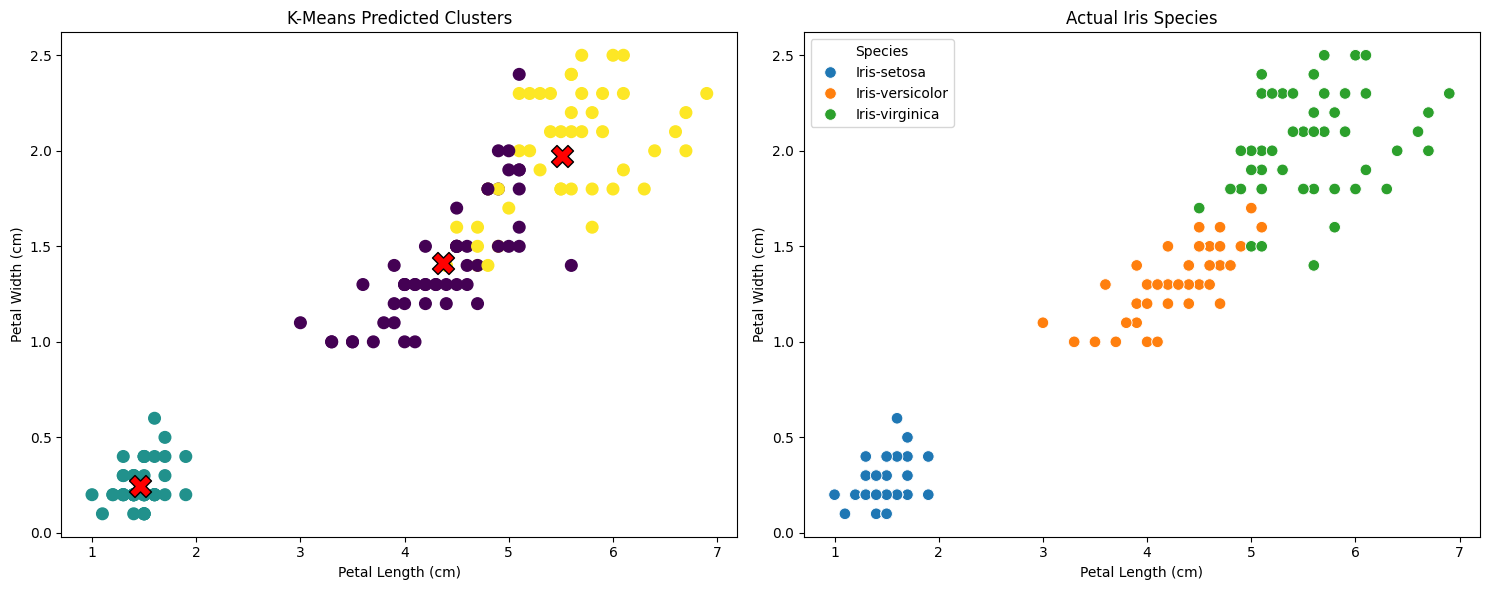

In [42]:
# Combined final visualization

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Predicted clusters
axes[0].scatter(
    X["PetalLengthCm"],
    X["PetalWidthCm"],
    c=cluster_labels,
    cmap="viridis",
    s=70
)

axes[0].scatter(
    centroids_original[:, 2],
    centroids_original[:, 3],
    marker="X",
    color="red",
    s=250,
    edgecolor="black"
)

axes[0].set_title("K-Means Predicted Clusters")
axes[0].set_xlabel("Petal Length (cm)")
axes[0].set_ylabel("Petal Width (cm)")


# Plot 2: Actual species
sns.scatterplot(
    x=X["PetalLengthCm"],
    y=X["PetalWidthCm"],
    hue=actual_species,
    ax=axes[1],
    s=70
)

axes[1].set_title("Actual Iris Species")
axes[1].set_xlabel("Petal Length (cm)")
axes[1].set_ylabel("Petal Width (cm)")

plt.tight_layout()
plt.show()


## Observations

1. K-Means successfully grouped the Iris samples into three clusters.
2. Feature scaling was performed before clustering to prevent features with larger ranges from dominating distance calculations.
3. Cluster centroids represent the average feature values of the generated clusters.
4. The Elbow Method was used to examine the appropriate number of clusters.
5. The Silhouette Score was used to evaluate cluster compactness and separation.
6. The generated clusters were compared with the actual Iris species using a contingency table and Adjusted Rand Index.
7. The visualization showed that some flower groups were more clearly separated than others.
8. Cluster labels do not directly correspond to the original species labels.



##  Conclusion

In this experiment, the K-Means clustering algorithm was implemented using the Iris dataset obtained from Kaggle.

The dataset was explored, preprocessed, and standardized before applying the clustering algorithm.

K-Means was used to group similar flower samples into three clusters based on their numerical features.

The resulting clusters and centroids were visualized using scatter plots and PCA. The Elbow Method was used to examine the appropriate number of clusters, while the Silhouette Score and Adjusted Rand Index were used to evaluate clustering performance.

This experiment demonstrated how an unsupervised learning algorithm can discover patterns and group similar observations without using target labels during training.



## Export Results

The final clustering results are saved as a CSV file containing the original feature values, actual species labels, and generated cluster labels.

This file can be used for further analysis and comparison with other clustering algorithms.


In [43]:
# Save clustering results

df.to_csv("KMeans_Iris_Results.csv", index=False)

print("Results saved successfully!")

Results saved successfully!


In [44]:
from google.colab import files

files.download("KMeans_Iris_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>